In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time
import random
from sklearn.metrics import accuracy_score

In [2]:
from nn_functions import sigma, sigma_der, det_activations, grad, neural_network, nn_plot, predict

<p style="font-size:20px">My own model = sigmoid activation function, no regularization, SGD, no momentum</p>

In [4]:
df = pd.read_csv('hearing_test.csv')
df.head()

,age,physical_score,test_result
0,33.0,40.7,1
1,50.0,37.2,1
2,52.0,24.7,0
3,56.0,31.0,0
4,35.0,42.9,1


In [8]:
labels = np.unique(df['test_result'])
labels

array([0, 1], dtype=int64)

In [10]:
X = df.drop('test_result', axis=1)
y = df['test_result']

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

In [16]:
scaler = StandardScaler()
scaled_X_train = scaler.fit_transform(X_train)
scaled_X_test = scaler.transform(X_test)

In [18]:
y_train = np.array(pd.get_dummies(y_train, dtype=int))

Time taken: 10.753223419189453 seconds
Accuracy: 0.856


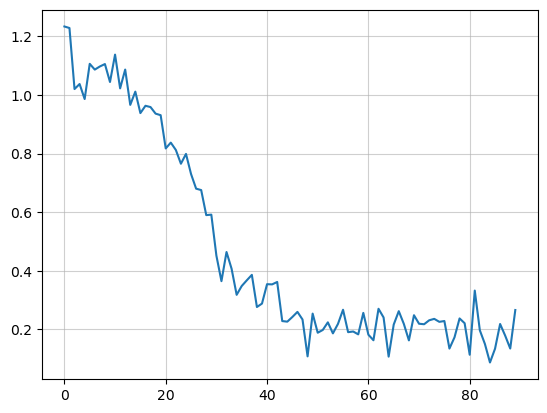

In [19]:
#inputs_train, outputs_train, inputs_test, outputs_test, labels, nodes, learning_rate, epochs, batch_size

weights, biases, cost = nn_plot(scaled_X_train, y_train, scaled_X_test, y_test, labels, [10, 10], 0.01, 10, 50)

Time taken: 30.46241807937622 seconds
Accuracy: 0.874


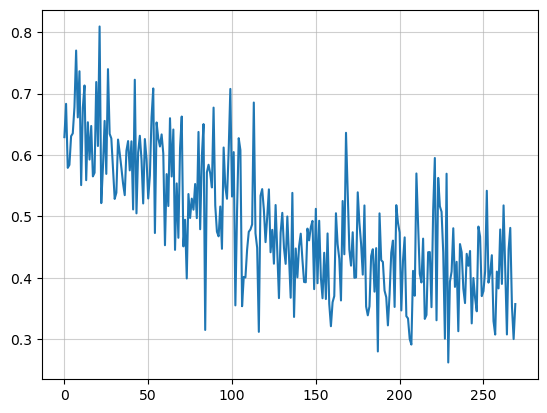

In [21]:
weights, biases, cost = nn_plot(scaled_X_train, y_train, scaled_X_test, y_test, labels, [10, 10], 0.01, 30, 50)

Time taken: 28.752739906311035 seconds
Accuracy: 0.892


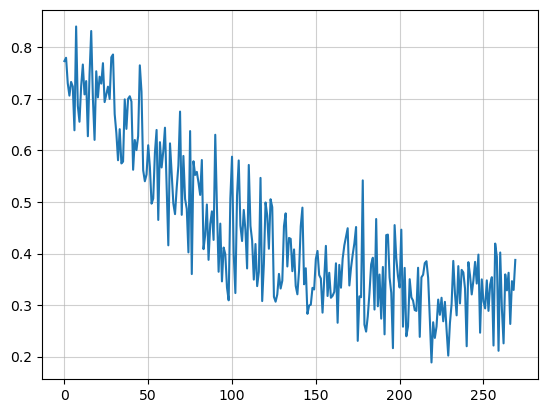

In [74]:
weights, biases, cost = nn_plot(scaled_X_train, y_train, scaled_X_test, y_test, labels, [10, 10], 0.001, 30, 50)

Time taken: 7.870865821838379 seconds
Accuracy: 0.912


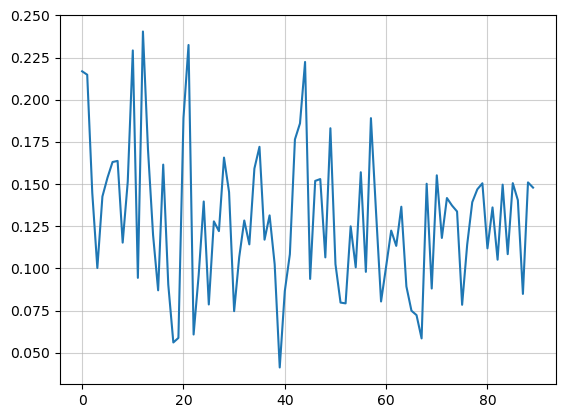

In [76]:
weights, biases, cost = nn_plot(scaled_X_train, y_train, scaled_X_test, y_test, labels, [5, 5], 0.1, 10, 50)

<p style="font-size:20px">MLPClassifier = relu activation function, regularization, SGD, momentum, Glorot/Xavier initialization</p>

In [79]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV

In [81]:
mlp = MLPClassifier(hidden_layer_sizes=(10,10), learning_rate_init=0.01, solver='sgd', batch_size=50)

In [85]:
mlp.fit(scaled_X_train, y_train)

MLPClassifier(batch_size=50, hidden_layer_sizes=(10, 10),
              learning_rate_init=0.01, solver='sgd')

In [37]:
y_pred = mlp.predict(scaled_X_test)

In [201]:
y_test = np.array(pd.get_dummies(y_test, dtype=int))

In [47]:
accuracy_score(y_pred, y_test)

0.918

In [53]:
mlp = MLPClassifier(max_iter=10000, random_state=42, batch_size=50, solver='sgd') 

param_grid = {'hidden_layer_sizes': [(5,), (10,), (15,), (5,5), (10, 10), (15, 15)],
              'learning_rate_init': [0.001, 0.01, 0.1]}

grid_mlp = GridSearchCV(mlp, param_grid=param_grid)

grid_mlp.fit(scaled_X_train, y_train)
grid_mlp.best_params_

{'hidden_layer_sizes': (5, 5), 'learning_rate_init': 0.1}

In [55]:
y_pred = grid_mlp.predict(scaled_X_test)
accuracy_score(y_pred, y_test)

0.916

<p style="font-size:20px">PyTorch</p>

In [20]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim

In [22]:
dataset = TensorDataset(torch.tensor(scaled_X_train), torch.tensor(y_train))
dataloader = DataLoader(dataset, batch_size=50, shuffle=True)
features = torch.tensor(scaled_X_test).float()

In [24]:
def run_model(model):

    start = time.time()  

    model.train()
    
    for i in range(num_epochs):
        for data in dataloader:
            optimizer.zero_grad()
            feature, target = data
            target = target.float()
            feature = feature.float()
            prediction = model(feature)    
            loss = criterion(prediction, target)    
            loss.backward()
            optimizer.step()
    
    end = time.time()
    print("Time taken:", round(end-start, 3), "seconds")
    print('')
    
    model.eval()
    
    with torch.no_grad():
        logits = model(features)   
        preds = torch.argmax(logits, dim=1)
    
    y_pred = pd.Series(preds.numpy()) 
    
    print('Accuracy score: ' + str(accuracy_score(y_pred, y_test)))

In [26]:
model = nn.Sequential(nn.Linear(2,5), nn.Linear(5,5), nn.Linear(5,2), nn.Sigmoid())
optimizer = optim.SGD(model.parameters(), lr=0.1)
criterion = nn.MSELoss()
num_epochs = 30

run_model(model)

Time taken: 6.808 seconds

Accuracy score: 0.906


In [39]:
model = nn.Sequential(nn.Linear(2,5), nn.Sigmoid(), nn.Linear(5,5), nn.Sigmoid(), nn.Linear(5,2), nn.Sigmoid())
optimizer = optim.SGD(model.parameters(), lr=0.1)
criterion = nn.MSELoss()
num_epochs = 30

run_model(model)

Time taken: 3.759 seconds

Accuracy score: 0.886


In [41]:
model = nn.Sequential(nn.Linear(2,5), nn.ReLU(), nn.Linear(5,5), nn.ReLU(), nn.Linear(5,2), nn.Sigmoid())
optimizer = optim.SGD(model.parameters(), lr=0.1)
criterion = nn.MSELoss()
num_epochs = 30

run_model(model)

Time taken: 2.429 seconds

Accuracy score: 0.906


In [43]:
model = nn.Sequential(nn.Linear(2,5), nn.Linear(5,5), nn.Linear(5,2), nn.Sigmoid())
optimizer = optim.SGD(model.parameters(), lr=0.1)
criterion = nn.MSELoss()
num_epochs = 300

run_model(model)

Time taken: 35.105 seconds

Accuracy score: 0.908


In [45]:
model = nn.Sequential(nn.Linear(2,5), nn.ReLU(), nn.Linear(5,5), nn.ReLU(), nn.Linear(5,2), nn.Sigmoid())
optimizer = optim.SGD(model.parameters(), lr=0.1)
criterion = nn.MSELoss()
num_epochs = 300

run_model(model)

Time taken: 42.839 seconds

Accuracy score: 0.914


In [47]:
model = nn.Sequential(nn.Linear(2,5), nn.ReLU(), nn.Linear(5,5), nn.ReLU(), nn.Linear(5,2), nn.Sigmoid())
optimizer = optim.SGD(model.parameters(), lr=0.1)
criterion = nn.MSELoss()
num_epochs = 1500

run_model(model)

Time taken: 210.424 seconds

Accuracy score: 0.912
